In [3]:
import os, numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import roc_auc_score, confusion_matrix

torch.manual_seed(42)
sp = pd.read_csv("data/splits.csv")
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
aug = transforms.Compose([transforms.RandomAffine(8, translate=(0.05, 0.05), scale=(0.95, 1.05)),
                          transforms.ToTensor(), norm])
plain = transforms.Compose([transforms.ToTensor(), norm])

class XR(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        img = Image.open(f"data/processed/{r.patientId}.png").convert("RGB")
        return self.tf(img), torch.tensor(float(r.label))

mk = lambda s, tf, sh: DataLoader(XR(sp[sp.split == s], tf), batch_size=16, shuffle=sh)
tr_dl, va_dl, te_dl = mk("train", aug, True), mk("val", plain, False), mk("test", plain, False)
print({s: int((sp.split == s).sum()) for s in ["train", "val", "test"]})

{'train': 420, 'val': 60, 'test': 120}


In [4]:
m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
for p in m.parameters(): p.requires_grad = False
for p in list(m.features.denseblock4.parameters()) + list(m.features.norm5.parameters()):
    p.requires_grad = True
m.classifier = nn.Linear(1024, 1)
opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-4)
lossf = nn.BCEWithLogitsLoss()

def predict(dl):
    m.eval(); ps, ys = [], []
    with torch.no_grad():
        for x, y in dl:
            ps += torch.sigmoid(m(x).squeeze(1)).tolist(); ys += y.tolist()
    return np.array(ps), np.array(ys)

In [5]:
os.makedirs("models", exist_ok=True)
best = 0
for ep in range(1, 9):
    m.train(); tot = 0
    for x, y in tr_dl:
        opt.zero_grad(); l = lossf(m(x).squeeze(1), y); l.backward(); opt.step(); tot += l.item()
    p, y = predict(va_dl)
    auc = roc_auc_score(y, p) if len(set(y)) > 1 else 0
    print(f"epoch {ep}  train loss {tot/len(tr_dl):.3f}  val AUC {auc:.3f}")
    if auc >= best: best = auc; torch.save(m.state_dict(), "models/densenet_pneumonia.pt")

epoch 1  train loss 0.592  val AUC 0.829
epoch 2  train loss 0.516  val AUC 0.817
epoch 3  train loss 0.503  val AUC 0.827
epoch 4  train loss 0.445  val AUC 0.834
epoch 5  train loss 0.416  val AUC 0.833
epoch 6  train loss 0.379  val AUC 0.829
epoch 7  train loss 0.340  val AUC 0.811
epoch 8  train loss 0.326  val AUC 0.821


In [6]:
m.load_state_dict(torch.load("models/densenet_pneumonia.pt"))
p, y = predict(te_dl)
tn, fp, fn, tp = confusion_matrix(y, p >= 0.5).ravel()
print("test AUC:", round(roc_auc_score(y, p), 3), "| accuracy:", round((tp + tn) / len(y), 3))
print("sensitivity (pneumonia caught):", round(tp / (tp + fn), 3), "| specificity (normal kept):", round(tn / (tn + fp), 3))
print("confusion [tn fp fn tp]:", tn, fp, fn, tp)

test AUC: 0.826 | accuracy: 0.742
sensitivity (pneumonia caught): 0.833 | specificity (normal kept): 0.65
confusion [tn fp fn tp]: 39 21 10 50


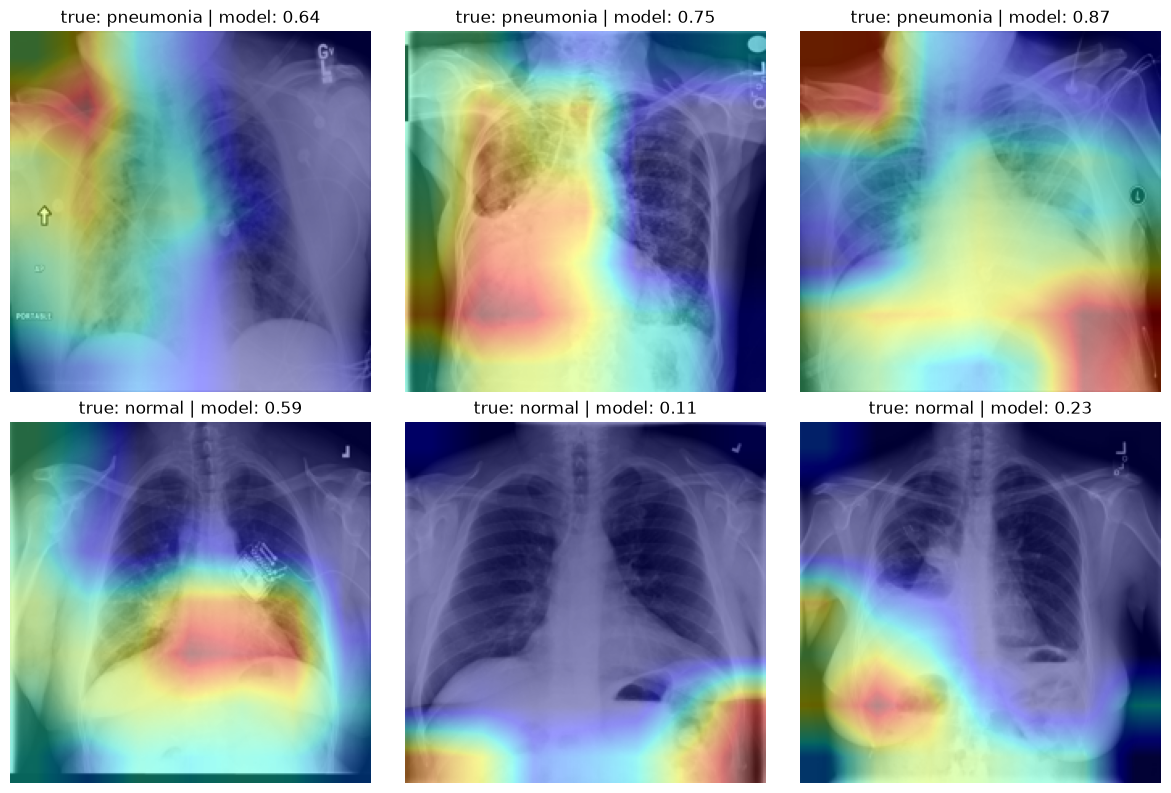

In [7]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

def gradcam(pid):
    img = Image.open(f"data/processed/{pid}.png").convert("RGB")
    x = plain(img).unsqueeze(0)
    m.eval(); m.zero_grad()
    f = m.features(x)
    r = F.relu(f); r.retain_grad()
    out = m.classifier(torch.flatten(F.adaptive_avg_pool2d(r, 1), 1))
    out.sum().backward()
    w = r.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * r).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear")[0, 0].detach().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return img, cam, torch.sigmoid(out).item()

os.makedirs("docs/gradcam", exist_ok=True)
test = sp[sp.split == "test"]
pick = pd.concat([test[test.label == 1].head(3), test[test.label == 0].head(3)])
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for a, (_, r) in zip(ax.ravel(), pick.iterrows()):
    img, cam, p = gradcam(r.patientId)
    a.imshow(img); a.imshow(cam, cmap="jet", alpha=0.4); a.axis("off")
    a.set_title(f"true: {'pneumonia' if r.label else 'normal'} | model: {p:.2f}")
plt.tight_layout(); plt.savefig("docs/gradcam/examples.png", dpi=120); plt.show()

In [8]:
%%writefile docker/docker-compose.yml
services:
  orthanc:
    image: orthancteam/orthanc:latest
    container_name: medical-orthanc
    ports:
      - "8042:8042"
      - "4242:4242"
    environment:
      ORTHANC__REMOTE_ACCESS_ALLOWED: "true"
      ORTHANC__AUTHENTICATION_ENABLED: "false"
    volumes:
      - orthanc-data:/var/lib/orthanc/db
volumes:
  orthanc-data:

Overwriting docker/docker-compose.yml


In [9]:
import requests, glob
files = sorted(glob.glob("data/images/*.dcm"))[:10]
for f in files:
    r = requests.post("http://localhost:8042/instances", data=open(f, "rb").read(),
                      headers={"Content-Type": "application/dicom"})
    print(r.status_code, r.json().get("Status"))
print(len(requests.get("http://localhost:8042/studies").json()), "studies in Orthanc")

200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
200 AlreadyStored
10 studies in Orthanc


In [10]:
%%writefile src/inference.py
import io, os, sys, time, sqlite3
import numpy as np, requests, pydicom, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from torchvision import transforms, models
from matplotlib import colormaps

ORTHANC = "http://localhost:8042"
DB = "data/results.db"
os.makedirs("data/results", exist_ok=True)

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
plain = transforms.Compose([transforms.ToTensor(), norm])

m = models.densenet121(weights=None)
m.classifier = nn.Linear(1024, 1)
m.load_state_dict(torch.load("models/densenet_pneumonia.pt", map_location="cpu"))
m.eval()

con = sqlite3.connect(DB)
con.execute("""CREATE TABLE IF NOT EXISTS results (
    study_id TEXT PRIMARY KEY, patient_id TEXT, score REAL, overlay_path TEXT,
    status TEXT DEFAULT 'pending', decision TEXT, decided_at REAL, created_at REAL)""")
con.commit()


def preprocess(ds):
    a = ds.pixel_array.astype("float32")
    lo, hi = np.percentile(a, [1, 99])
    a = np.clip((a - lo) / (hi - lo + 1e-6), 0, 1)
    return Image.fromarray((a * 255).astype("uint8")).resize((224, 224)).convert("RGB")


def gradcam(img):
    x = plain(img).unsqueeze(0)
    m.zero_grad()
    r = F.relu(m.features(x)); r.retain_grad()
    out = m.classifier(torch.flatten(F.adaptive_avg_pool2d(r, 1), 1))
    out.sum().backward()
    w = r.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * r).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear")[0, 0].detach().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, torch.sigmoid(out).item()


def process(study_id):
    inst = requests.get(f"{ORTHANC}/studies/{study_id}/instances").json()[0]["ID"]
    raw = requests.get(f"{ORTHANC}/instances/{inst}/file").content
    ds = pydicom.dcmread(io.BytesIO(raw))
    img = preprocess(ds)
    cam, score = gradcam(img)
    heat = (colormaps["jet"](cam)[..., :3] * 255).astype("uint8")
    overlay = Image.blend(img, Image.fromarray(heat), 0.4)
    path = f"data/results/{study_id}.png"
    overlay.save(path)
    con.execute("INSERT OR REPLACE INTO results (study_id, patient_id, score, overlay_path, created_at) VALUES (?,?,?,?,?)",
                (study_id, str(ds.get("PatientID", "")), score, path, time.time()))
    con.commit()
    print(f"scored {study_id[:8]}... score {score:.3f}")


def run_once():
    done = {r[0] for r in con.execute("SELECT study_id FROM results")}
    new = [s for s in requests.get(f"{ORTHANC}/studies").json() if s not in done]
    for s in new:
        process(s)
    return len(new)


if __name__ == "__main__":
    if "--once" in sys.argv:
        print("processed", run_once(), "new studies")
    else:
        while True:
            run_once(); time.sleep(5)

Overwriting src/inference.py


In [11]:
import sqlite3, pandas as pd
print(pd.read_sql("SELECT study_id, patient_id, score, status FROM results", sqlite3.connect("data/results.db")))

                                       study_id  \
0  07093c88-4ce902ca-e7ad09f9-cdb93d48-319539c9   
1  0db83f28-40733157-e222b896-8801fb0e-c99d2318   
2  1647f93a-3f504a34-e6b8ee9f-a2c18b5c-db7ed864   
3  47348161-e4183527-f5087f86-eae18a64-1edf0451   
4  4b18bd91-ef45d059-55325968-72b71c5f-5732bb96   
5  8150fc45-e1a304ed-07cc9937-26fcc417-9219dc38   
6  818e294d-7ffee72c-afe45814-512b93d0-9c44519c   
7  86325d8a-b76b4512-49990759-031bc421-6bd06c17   
8  ad976f7f-8ff9d48e-a03414d0-43ad43c5-a16f3121   
9  b7fa1f86-34a2d352-02cd96d6-c88f062b-fad2d852   

                             patient_id     score    status  
0  04e9f692-f3d6-496b-ae0c-905137cc1f84  0.584169   pending  
1  020a16e3-baf9-4cf0-859c-c79b5253d717  0.723313   pending  
2  02ea6b76-4189-47c5-a8bf-70590f84ebd8  0.862274   pending  
3  04e6f392-a196-447f-9b75-f5af995a36d0  0.582583   pending  
4  01f3abc2-33c7-4ea2-a599-dc49b76fcfae  0.833601   pending  
5  0727efd2-c063-4409-b326-9532f6531a97  0.239612   pending  
6  0

In [12]:
%%writefile src/viewer_api.py
import sqlite3, time, requests
from fastapi import FastAPI, HTTPException
from fastapi.responses import FileResponse, Response
from pydantic import BaseModel

ORTHANC = "http://localhost:8042"
DB = "data/results.db"
app = FastAPI(title="Medical imaging viewer API")


def db():
    c = sqlite3.connect(DB)
    c.row_factory = sqlite3.Row
    c.execute("""CREATE TABLE IF NOT EXISTS audit (
        id INTEGER PRIMARY KEY AUTOINCREMENT, study_id TEXT, action TEXT,
        reviewer TEXT, ai_score REAL, at REAL)""")
    return c


class Decision(BaseModel):
    study_id: str
    decision: str      # "approve" or "reject"
    reviewer: str


@app.get("/")
def home():
    return FileResponse("src/viewer.html")


@app.get("/cases")
def cases():
    c = db()
    rows = c.execute("SELECT study_id, patient_id, score, status, decision FROM results "
                     "ORDER BY (status='pending') DESC, score DESC").fetchall()
    return [dict(r) for r in rows]


@app.get("/overlay/{study_id}")
def overlay(study_id: str):
    r = db().execute("SELECT overlay_path FROM results WHERE study_id=?", (study_id,)).fetchone()
    if not r:
        raise HTTPException(404, "unknown study")
    return FileResponse(r["overlay_path"])


@app.get("/scan/{study_id}")
def scan(study_id: str):
    inst = requests.get(f"{ORTHANC}/studies/{study_id}/instances").json()[0]["ID"]
    img = requests.get(f"{ORTHANC}/instances/{inst}/preview")
    return Response(img.content, media_type="image/png")


@app.post("/decision")
def decide(d: Decision):
    if d.decision not in ("approve", "reject"):
        raise HTTPException(400, "decision must be approve or reject")
    c = db()
    r = c.execute("SELECT score FROM results WHERE study_id=?", (d.study_id,)).fetchone()
    if not r:
        raise HTTPException(404, "unknown study")
    now = time.time()
    c.execute("UPDATE results SET status='reviewed', decision=?, decided_at=? WHERE study_id=?",
              (d.decision, now, d.study_id))
    c.execute("INSERT INTO audit (study_id, action, reviewer, ai_score, at) VALUES (?,?,?,?,?)",
              (d.study_id, d.decision, d.reviewer, r["score"], now))
    c.commit()
    return {"ok": True}


@app.get("/audit")
def audit():
    rows = db().execute("SELECT * FROM audit ORDER BY id DESC LIMIT 50").fetchall()
    return [dict(r) for r in rows]

Overwriting src/viewer_api.py


In [13]:
%%writefile src/viewer.html
<!doctype html>
<html><head><meta charset="utf-8"><title>AI Chest X-ray Viewer</title>
<style>
body{font-family:Segoe UI,Arial,sans-serif;margin:0;background:#f4f6f8;color:#1f2a44}
.banner{background:#b42318;color:#fff;padding:10px 20px;font-weight:600}
.wrap{display:flex;gap:16px;padding:16px}
.list{width:260px}.item{padding:8px 10px;margin-bottom:6px;background:#fff;border-radius:6px;cursor:pointer;border:2px solid transparent;font-size:13px}
.item.sel{border-color:#0f766e}.main{flex:1}.imgs{display:flex;gap:12px}
.imgs div{background:#000;color:#fff;text-align:center;font-size:12px;border-radius:6px;padding-bottom:6px}
.imgs img{width:100%;max-width:380px;display:block}
button{padding:10px 22px;border:0;border-radius:6px;font-size:15px;cursor:pointer;color:#fff;margin-right:8px}
.ok{background:#0f766e}.no{background:#b42318}
table{border-collapse:collapse;background:#fff;width:100%;font-size:12px}td,th{border:1px solid #d5dde0;padding:5px 8px}
</style></head><body>
<div class="banner">FOR EDUCATION ONLY. NOT FOR CLINICAL USE. AI output may be wrong and must not guide patient care.</div>
<div id="root"></div>
<script src="https://cdn.jsdelivr.net/npm/react@18.3.1/umd/react.production.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/react-dom@18.3.1/umd/react-dom.production.min.js"></script>
<script>
const h = React.createElement, {useState, useEffect} = React;
function App() {
  const [cases, setCases] = useState([]), [sel, setSel] = useState(null);
  const [audit, setAudit] = useState([]), [who, setWho] = useState("");
  const load = () => {
    fetch("/cases").then(r => r.json()).then(d => { setCases(d); setSel(s => s || (d[0] && d[0].study_id)); });
    fetch("/audit").then(r => r.json()).then(setAudit);
  };
  useEffect(load, []);
  const cur = cases.find(c => c.study_id === sel);
  const decide = d => {
    if (!who.trim()) { alert("Enter the reviewer name first"); return; }
    fetch("/decision", {method: "POST", headers: {"Content-Type": "application/json"},
      body: JSON.stringify({study_id: sel, decision: d, reviewer: who})}).then(load);
  };
  return h("div", {className: "wrap"},
    h("div", {className: "list"}, h("h3", null, "Studies"),
      cases.map(c => h("div", {key: c.study_id, className: "item" + (c.study_id === sel ? " sel" : ""), onClick: () => setSel(c.study_id)},
        c.study_id.slice(0, 8) + "...  AI " + c.score.toFixed(2) + "  [" + (c.decision || "pending") + "]"))),
    h("div", {className: "main"},
      cur ? h("div", null,
        h("div", {className: "imgs"},
          h("div", null, h("img", {src: "/scan/" + sel}), "Original scan"),
          h("div", null, h("img", {src: "/overlay/" + sel}), "AI heatmap (Grad-CAM)")),
        h("h3", null, "AI confidence for pneumonia: " + (cur.score * 100).toFixed(1) + "%"),
        h("p", null, "Status: " + (cur.decision || "pending review")),
        h("input", {placeholder: "Reviewer name", value: who, onChange: e => setWho(e.target.value), style: {padding: 8, marginRight: 10}}),
        h("button", {className: "ok", onClick: () => decide("approve")}, "Approve"),
        h("button", {className: "no", onClick: () => decide("reject")}, "Reject")
      ) : h("p", null, "No studies yet. Run inference first."),
      h("h3", null, "Audit log"),
      h("table", null, h("tr", null, ["Time", "Study", "Action", "Reviewer", "AI score"].map(t => h("th", {key: t}, t))),
        audit.map(a => h("tr", {key: a.id}, h("td", null, new Date(a.at * 1000).toLocaleString()),
          h("td", null, a.study_id.slice(0, 8)), h("td", null, a.action), h("td", null, a.reviewer), h("td", null, a.ai_score.toFixed(3)))))));
}
ReactDOM.createRoot(document.getElementById("root")).render(h(App));
</script></body></html>

Overwriting src/viewer.html


In [14]:
for f in ["src/inference.py", "src/viewer_api.py"]:
    t = open(f).read()
    t = t.replace('ORTHANC = "http://localhost:8042"',
                  'ORTHANC = os.environ.get("ORTHANC_URL", "http://localhost:8042")')
    if "import os" not in t:
        t = "import os\n" + t
    open(f, "w").write(t)
    print(f, "ORTHANC_URL" in t)

src/inference.py True
src/viewer_api.py True


In [15]:
%%writefile docker/Dockerfile.app
FROM python:3.14-slim
WORKDIR /app
RUN pip install --no-cache-dir --default-timeout=200 --retries 10 torch torchvision --index-url https://download.pytorch.org/whl/cpu
RUN pip install --no-cache-dir --default-timeout=200 --retries 10 fastapi uvicorn requests pydicom pillow numpy matplotlib
RUN python -c "import torch, torchvision, pydicom, fastapi, matplotlib; print('deps ok')"
COPY src src
EXPOSE 8001
CMD ["uvicorn", "src.viewer_api:app", "--host", "0.0.0.0", "--port", "8001"]

Overwriting docker/Dockerfile.app


In [16]:
%%writefile docker/docker-compose.yml
services:
  orthanc:
    image: orthancteam/orthanc:latest
    container_name: medical-orthanc
    ports:
      - "8042:8042"
      - "4242:4242"
    environment:
      ORTHANC__REMOTE_ACCESS_ALLOWED: "true"
      ORTHANC__AUTHENTICATION_ENABLED: "false"
    volumes:
      - orthanc-data:/var/lib/orthanc/db
  viewer:
    build:
      context: ..
      dockerfile: docker/Dockerfile.app
    container_name: medical-viewer
    ports:
      - "8001:8001"
    environment:
      ORTHANC_URL: "http://orthanc:8042"
    volumes:
      - ../data:/app/data
      - ../models:/app/models
    depends_on:
      - orthanc
  inference:
    build:
      context: ..
      dockerfile: docker/Dockerfile.app
    container_name: medical-inference
    command: ["python", "src/inference.py"]
    environment:
      ORTHANC_URL: "http://orthanc:8042"
    volumes:
      - ../data:/app/data
      - ../models:/app/models
    depends_on:
      - orthanc
volumes:
  orthanc-data:

Overwriting docker/docker-compose.yml


In [17]:
from sklearn.metrics import roc_auc_score, confusion_matrix

m.load_state_dict(torch.load("models/densenet_pneumonia.pt"))
p, y = predict(te_dl)
y = y.astype(int)
n_tr, n_va, n_te = [int((sp.split == s).sum()) for s in ["train", "val", "test"]]
n_pos, n_neg = int((sp.label == 1).sum()), int((sp.label == 0).sum())

tn, fp, fn, tp = confusion_matrix(y, p >= 0.5).ravel()
auc = roc_auc_score(y, p)
sens, spec = tp / (tp + fn), tn / (tn + fp)

rng = np.random.default_rng(42)
boots = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    if len(set(y[i])) > 1:
        boots.append(roc_auc_score(y[i], p[i]))
lo, hi = np.percentile(boots, [2.5, 97.5])

if n_te < 100:
    print("WARNING: only", n_te, "test images. Do not publish these numbers. Finish the 600-image download first.")

card = f"""# Model Card: Chest X-ray Pneumonia Classifier

**FOR EDUCATION ONLY. NOT FOR CLINICAL USE.**

## Model
DenseNet121 pre-trained on ImageNet. Only the last dense block and a new output layer were trained (transfer learning). Input: chest X-ray resized to 224x224.

## Data
RSNA Pneumonia Detection Challenge (Kaggle), DICOM format. A random subset of {n_pos + n_neg} patients: {n_pos} with pneumonia labels and {n_neg} without. Split: {n_tr} train, {n_va} validation, {n_te} test, stratified by label.

## Measured results (test set, {n_te} images, threshold 0.5)
- AUC: {auc:.3f} (95% bootstrap interval {lo:.3f} to {hi:.3f})
- Sensitivity (pneumonia caught): {sens:.3f} ({tp} of {tp + fn})
- Specificity (normal kept): {spec:.3f} ({tn} of {tn + fp})
- Confusion matrix [tn fp fn tp]: {tn} {fp} {fn} {tp}
These come from one small test set, so they carry wide uncertainty.

## Limits
- Trained on a small subset using a CPU, so performance is far below a clinical-grade system.
- The classes were balanced to 50/50 for training. Real pneumonia prevalence is much lower, so precision in real use would be lower than shown here.
- One dataset, one source. The model has not been tested on other hospitals, scanners or protocols.
- Labels come from the challenge annotations, not from my own radiology review.
- Grad-CAM shows where the model looked, not that it is correct. Heat on image borders, markers or tubes would signal shortcut learning.
- The viewer runs without login, and Orthanc authentication is off. This is a local demo only.

## Possible bias
- The data comes from a single source population, so age, sex, body size and equipment differences are not represented evenly. Subgroup performance was not measured.
- Portable and bedside X-rays often show more severe cases, so the model may learn the scan type instead of the disease.
- I did not audit performance by sex or age because the preprocessed images no longer carry that information.

## Intended use
Learning how a DICOM, inference and review workflow fits together. Not for diagnosis, triage or any decision about a patient.
"""
os.makedirs("docs", exist_ok=True)
open("docs/model_card.md", "w", encoding="utf-8").write(card)
print(card[card.index("## Data"):card.index("## Limits")])

## Data
RSNA Pneumonia Detection Challenge (Kaggle), DICOM format. A random subset of 600 patients: 300 with pneumonia labels and 300 without. Split: 420 train, 60 validation, 120 test, stratified by label.

## Measured results (test set, 120 images, threshold 0.5)
- AUC: 0.826 (95% bootstrap interval 0.743 to 0.889)
- Sensitivity (pneumonia caught): 0.833 (50 of 60)
- Specificity (normal kept): 0.650 (39 of 60)
- Confusion matrix [tn fp fn tp]: 39 21 10 50
These come from one small test set, so they carry wide uncertainty.




In [18]:
%%writefile docker/docker-compose.yml
services:
  orthanc:
    image: orthancteam/orthanc:latest
    container_name: medical-orthanc
    ports:
      - "8042:8042"
      - "4242:4242"
    environment:
      ORTHANC__REMOTE_ACCESS_ALLOWED: "true"
      ORTHANC__AUTHENTICATION_ENABLED: "false"
    volumes:
      - orthanc-data:/var/lib/orthanc/db
  viewer:
    image: docker-viewer
    container_name: medical-viewer
    ports:
      - "8001:8001"
    environment:
      ORTHANC_URL: "http://orthanc:8042"
    volumes:
      - results-data:/app/data
      - ../models:/app/models:ro
    depends_on:
      - orthanc
  inference:
    image: docker-inference
    container_name: medical-inference
    command: ["python", "src/inference.py"]
    environment:
      ORTHANC_URL: "http://orthanc:8042"
    volumes:
      - results-data:/app/data
      - ../models:/app/models:ro
    depends_on:
      - orthanc
volumes:
  orthanc-data:
  results-data:

Overwriting docker/docker-compose.yml


In [19]:
import requests
print(len(requests.get("http://localhost:8042/studies").json()), "studies in Orthanc")

10 studies in Orthanc


In [20]:
from sklearn.metrics import roc_auc_score, confusion_matrix

m.load_state_dict(torch.load("models/densenet_pneumonia.pt"))
p, y = predict(te_dl)
y = y.astype(int)
n_tr, n_va, n_te = [int((sp.split == s).sum()) for s in ["train", "val", "test"]]
n_pos, n_neg = int((sp.label == 1).sum()), int((sp.label == 0).sum())

tn, fp, fn, tp = confusion_matrix(y, p >= 0.5).ravel()
auc = roc_auc_score(y, p)
sens, spec = tp / (tp + fn), tn / (tn + fp)

rng = np.random.default_rng(42)
boots = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    if len(set(y[i])) > 1:
        boots.append(roc_auc_score(y[i], p[i]))
lo, hi = np.percentile(boots, [2.5, 97.5])

if n_te < 100:
    print("WARNING: only", n_te, "test images. Do not use these numbers.")

card = f"""# Model Card: Chest X-ray Pneumonia Classifier

**FOR EDUCATION ONLY. NOT FOR CLINICAL USE.**

## Model
DenseNet121 pre-trained on ImageNet. Only the last dense block and a new output layer were trained (transfer learning). Input: chest X-ray resized to 224x224.

## Data
RSNA Pneumonia Detection Challenge (Kaggle), DICOM format. A random subset of {n_pos + n_neg} patients: {n_pos} with pneumonia labels and {n_neg} without. Split: {n_tr} train, {n_va} validation, {n_te} test, stratified by label.

## Measured results (test set, {n_te} images, threshold 0.5)
- AUC: {auc:.3f} (95% bootstrap interval {lo:.3f} to {hi:.3f})
- Sensitivity (pneumonia caught): {sens:.3f} ({tp} of {tp + fn})
- Specificity (normal kept): {spec:.3f} ({tn} of {tn + fp})
- Confusion matrix [tn fp fn tp]: {tn} {fp} {fn} {tp}
These come from one small test set, so they carry wide uncertainty.

## Limits
- Trained on a small subset using a CPU, so performance is far below a clinical-grade system.
- The classes were balanced to 50/50 for training. Real pneumonia prevalence is much lower, so precision in real use would be lower than shown here.
- One dataset, one source. The model has not been tested on other hospitals, scanners or protocols.
- Labels come from the challenge annotations, not from my own radiology review.
- Grad-CAM shows where the model looked, not that it is correct. Heat on image borders, markers or tubes would signal shortcut learning.
- The viewer runs without login, and Orthanc authentication is off. This is a local demo only.

## Possible bias
- The data comes from a single source population, so age, sex, body size and equipment differences are not represented evenly. Subgroup performance was not measured.
- Portable and bedside X-rays often show more severe cases, so the model may learn the scan type instead of the disease.
- I did not audit performance by sex or age because the preprocessed images no longer carry that information.

## Intended use
Learning how a DICOM, inference and review workflow fits together. Not for diagnosis, triage or any decision about a patient.
"""
os.makedirs("docs", exist_ok=True)
open("docs/model_card.md", "w", encoding="utf-8").write(card)
print(card[card.index("## Data"):card.index("## Limits")])

## Data
RSNA Pneumonia Detection Challenge (Kaggle), DICOM format. A random subset of 600 patients: 300 with pneumonia labels and 300 without. Split: 420 train, 60 validation, 120 test, stratified by label.

## Measured results (test set, 120 images, threshold 0.5)
- AUC: 0.826 (95% bootstrap interval 0.743 to 0.889)
- Sensitivity (pneumonia caught): 0.833 (50 of 60)
- Specificity (normal kept): 0.650 (39 of 60)
- Confusion matrix [tn fp fn tp]: 39 21 10 50
These come from one small test set, so they carry wide uncertainty.




In [21]:
card = open("docs/model_card.md", encoding="utf-8").read()
results = card[card.index("## Measured results"):card.index("## Limits")].replace("## Measured results", "### Measured results")

readme = f"""# AI-Assisted Medical Imaging and Diagnosis System (AIML-02)

**FOR EDUCATION ONLY. NOT FOR CLINICAL USE.**

A platform where a chest X-ray (DICOM) is stored on a DICOM server, analysed by a deep learning model, shown to a reviewer with an explanation heatmap, and approved or rejected, with every decision written to an audit log.

**Dataset:** RSNA Pneumonia Detection Challenge (Kaggle), a balanced subset of 600 patients.

## Architecture

```mermaid
flowchart LR
    X[DICOM X-ray] --> O[Orthanc DICOM server]
    O --> I[Inference service: DenseNet121 + Grad-CAM]
    I --> D[(Results database)]
    D --> V[Viewer API: FastAPI]
    O --> V
    V --> R[React viewer: scan, heatmap, score]
    R -->|Approve or Reject| A[(Audit log)]
```

## Tech stack
PyTorch, torchvision (DenseNet121), pydicom, Orthanc, Grad-CAM, FastAPI, React, Docker.

## What I built
1. Learned the DICOM format and read pixel data with pydicom.
2. Preprocessed images: percentile normalization and resize to 224x224.
3. Split patients into train, validation and test sets, stratified by label.
4. Trained a DenseNet121 classifier with transfer learning: only the last dense block and the new output layer were trained.
5. Added Grad-CAM, which shows the region that influenced each prediction (examples in `docs/gradcam/examples.png`).
6. Ran an Orthanc DICOM server in Docker and wrote an inference service that pulls new studies, scores them, and stores the heatmap.
7. Built a React viewer with the scan, the AI overlay, the confidence score and Approve/Reject buttons.
8. Logged every decision (reviewer, action, AI score, time) in an audit table.
9. Containerized Orthanc, the viewer and the inference service with Docker Compose.

{results}
See `docs/model_card.md` for the full model card: limits and possible bias.

## Limits
- The model was trained on a small subset using a CPU, so it is far from clinical grade.
- Training classes were balanced 50/50, so precision in real use would be lower.
- Results come from one small test set and carry wide uncertainty.
- A segmentation model was not built because of time and CPU limits.
- Data versioning with DVC was not completed.
- The viewer has no login and Orthanc authentication is off: local demo only.
- The React page loads React from a CDN (no build step), so it needs internet.
- Grad-CAM shows where the model looked, not that it is correct.

## How to run it
```
python -m venv venv
venv\\Scripts\\activate
pip install torch torchvision pydicom pandas scikit-learn pillow matplotlib fastapi uvicorn requests
kaggle competitions download -c rsna-pneumonia-detection-challenge -f stage_2_train_labels.csv -p data
```
Run `01_subset.ipynb` (download and preprocess), then `02_train.ipynb` (train, test, Grad-CAM). Then:
```
docker compose -f docker\\docker-compose.yml up -d
```
Upload studies to Orthanc at http://localhost:8042, then open the viewer at http://localhost:8001.
"""
open("README.md", "w", encoding="utf-8").write(readme)
print(readme[:700])

# AI-Assisted Medical Imaging and Diagnosis System (AIML-02)

**FOR EDUCATION ONLY. NOT FOR CLINICAL USE.**

A platform where a chest X-ray (DICOM) is stored on a DICOM server, analysed by a deep learning model, shown to a reviewer with an explanation heatmap, and approved or rejected, with every decision written to an audit log.

**Dataset:** RSNA Pneumonia Detection Challenge (Kaggle), a balanced subset of 600 patients.

## Architecture

```mermaid
flowchart LR
    X[DICOM X-ray] --> O[Orthanc DICOM server]
    O --> I[Inference service: DenseNet121 + Grad-CAM]
    I --> D[(Results database)]
    D --> V[Viewer API: FastAPI]
    O --> V
    V --> R[React viewer: scan, heatmap, score]
    R


In [1]:
t = open("src/viewer.html", encoding="utf-8").read()
old = ".imgs img{width:100%;max-width:380px;display:block}"
new = ".imgs img{width:380px;max-width:100%;display:block}"
assert old in t, "css line not found"
t = t.replace(old, new)
t = t.replace(".imgs div{background:#000;", ".imgs div{align-self:flex-start;background:#000;")
open("src/viewer.html", "w", encoding="utf-8").write(t)
print("viewer.html updated")

viewer.html updated


In [2]:
c = open("docker/docker-compose.yml", encoding="utf-8").read()
old = '''      - results-data:/app/data
      - ../models:/app/models:ro
    depends_on:
      - orthanc
  inference:'''
new = '''      - results-data:/app/data
      - ../models:/app/models:ro
      - ../src:/app/src:ro
    depends_on:
      - orthanc
  inference:'''
assert old in c, "compose block not found"
open("docker/docker-compose.yml", "w", encoding="utf-8").write(c.replace(old, new))
print("compose updated")

compose updated
